In [1]:
!pip install torch torchvision matplotlib

Matplotlib is building the font cache; this may take a moment.


Number of images: 60000 images
Number for the first item: 5
Tensor Shape: torch.Size([1, 28, 28])
Data Type: torch.float32
Maximum and Minimum Pixel Values: Min = 0.00, Max: 1.00
--- 5x5 Decimal Pixel Grid (Center Part) ---
0.75 0.99 0.27 0.00 0.00
0.14 0.95 0.88 0.63 0.42
0.00 0.32 0.94 0.99 0.99
0.00 0.00 0.18 0.73 0.99
0.00 0.00 0.00 0.06 0.36
--------------------------------------------


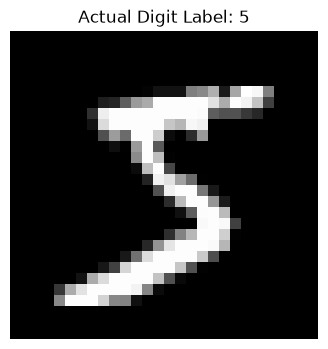

In [15]:
import torch #Loads all the PyTorch features providing Tensors
import torchvision #Loads image-handling tools so they don't need to be done from scratch (AI models, MNIST, image processing tools)
import torchvision.transforms as transforms #transforms = torchvision.transforms
# "torchvision.transforms" contains functions that convert/modify all images (image data) into a kind of data that a PyTorch Nueral Network would expect to recieve
import matplotlib.pyplot as plt

transforming = transforms.ToTensor() #the "ToTensor()" feature can be found in the "transforms" extenstion
#PyTorch networks are unable to read raw files directly so brightness values are converted to Tensor digits from 0.0 to 1.0
#This is a specific image-processing insturction, as the conversion to Tensor digits require the brightness digits to be from 0.0 to 1.0

mnist_data = torchvision.datasets.MNIST( #torchvision.datasets.MNIST is a helper function that automatically downloads, organizes and formats 70000 handwritten digits
    root='./data', #creates a folder named "data" so that the dataset files can be saved over there
    train=True, #indicates that the training set is going to be loaded (not the test)
    download=True, #if the dataset exists in './data' then do nothing, but if doesn't exist then download the dataset (70,000 numbers)
    transform=transforming #Apply the .ToTensor() feature that has been saved to variable "transforming"
)

first_image_tensor, label = mnist_data[0] #"first_image_tensor" is the image of the number formatted as a numerical grid and label is the answer
#the above line is done to just ensure that the program is working

print(f"Number of images: {len(mnist_data)} images")
print(f"Number for the first item: {label}")
print(f"Tensor Shape: {first_image_tensor.shape}") #.shape is given out in the format of ".Size[1, 32, 32]", 1 indicates that its in greyscale, while the first "32" indicates vertical height while the second "32" indicates horizontal height. All in pixels.
print(f"Data Type: {first_image_tensor.dtype}") #gives the type of "first_image_tensor", it is supposed to be a "torch.float" indicating that the pixels of first_image_tensor are read as decimals
print(f"Maximum and Minimum Pixel Values: Min = {first_image_tensor.min():.2f}, Max: {first_image_tensor.max():.2f}") #gives minimum and maximum values of all pixels for "first_image_tensor
#":" needed for printing the maximum and minimum as when using formatters such as ".2f", a ":" is mandatory right before

center_slice = first_image_tensor[0, 12:17, 12:17] #0 is our color channel, while the 12th to 16th vertical pixel and 12th to 16th horizontal pixel have been assigned to "center_slice"

print("--- 5x5 Decimal Pixel Grid (Center Part) ---") 
for row in center_slice: #for each row (as center_slice), are lists (that serve as horizontal rows) that succeed each other (in a way that replicates rows stacked on top of each other vertically)
    print(" ".join(f"{value:.2f}" for value in row)) #.join() in this case allows for a switch between "[0.24, 0.1]" to "0.24 0.1", and the f-string rounds all float numbers to 2 decimal places before converting it into a string so that ".join()" can be used on it. Nested for loop used.
print("--------------------------------------------")

image_2dim = first_image_tensor[0] #turns "first_image_tensor" from a 3D tensor to a 2D tensor, as matplotlib only accepts 2D Tensors

plt.figure(figsize=(4, 4)) #plt.figure() creates a blank canvas figure that is 4 inches by 4 inches, to determine size: figsize(width, height)
plt.imshow(image_2dim, cmap = 'gray') #in plt.inshow, the desire to plot "image_2dim" was declared under the grey(scale) color scheme
plt.title(f"Actual Digit Label: {label}") #plt.title allows us to plot the title
plt.axis("off") #plt.axis("off") enables us to remove the axis labels (i.e. tick marks, borderframes, coordinate markers)
plt.show()




<>:10: SyntaxWarning: invalid escape sequence '\d'
<>:10: SyntaxWarning: invalid escape sequence '\d'
/var/folders/v6/1f2888zj1b38j_4l673jlcj00000gn/T/ipykernel_56760/1355618227.py:10: SyntaxWarning: invalid escape sequence '\d'
  root='.\data',


<function matplotlib.pyplot.show(close=None, block=None)>

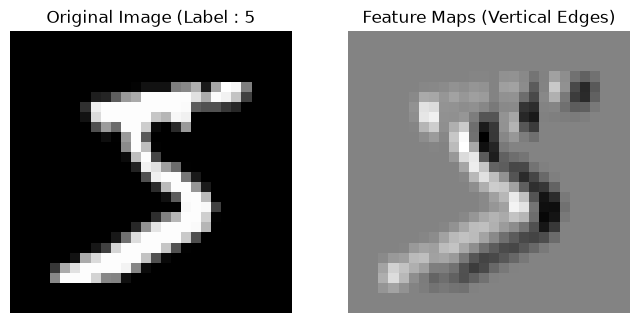

In [29]:
import torch
import torch.nn as nn #importing "torch.nn" (abbreviated "nn") means importing neural network "building blocks" (neural networks needed for the program to be able to identify edges)
import torchvision
import torchvision.transforms as transforms #Both needed to convert the 0 to 255 integer scale on pixels to 0.0 to 1.0 (that the neural networks can be able to read)
#QUESTION: Why do we need to mention "torchvision.transforms" alone when it is a part of the aformentioned "torchvision"
import matplotlib.pyplot as plt #imports matplotlib to be able to load the drawing library to depict output

transforming = transforms.ToTensor()

mnist_data = torchvision.datasets.MNIST( #when accessing a already-made dataset in PyTorch (torchvision.datasets), its "features" (root, train, download, transform) must be given
    root='.\data',
    train=True,
    download=True,
    transform=transforming
)

first_image, label = mnist_data[0] #mnist_data[0] has two components, an image of a number (first_image) and a label mentioning the number (label)

input_image = first_image.unsqueeze(0) #first_image is by default a 3D Tensor, "adding unsqueeze(0)" to "first_image" turns it into a 4D Tensor
#The above line was neccesary as Python neural networks are built strictly for processing batches and a 4D Tensor is formatted as "[Batch_Size, Color_Channels, Height, Width]"

convoluting = nn.Conv2d(in_channels=1, out_channels=1, kernel_size=3, padding=1) 
#QUESTION: Why do we care about preventing shrinking
#For the above line: nn.Conv2d() is required for the process of convolution to happen, "in_channels" represents the number of color channels for the input image (1), while "out_channels" represnts the number of outputted grids of numbers wanted (1), "kernel_size" is for the dimensions of the kernel (3 by 3) while "padding=1" ensures 1-pixel thick outermost layer of zeros ensuring output image is still 28 by 28 pixels (indicating no shrinking)

edge_kernel = torch.tensor([[[
    [-1.0, 0.0, 1.0],
    [-2.0, 0.0, 2.0],
    [-1.0, 0.0, 1.0]]]]) #.tensor() creates a custom tensor, the prescene of 4 "[]" indicates this is in a 4D shape even as kernel as 2D Tensors. This is because there are 4 features (in "convoluting) that the kernel must cater to ("in_channels" (number of color channels in the incoming image), "out_channels" (number of grid that one would like to output), "kernel_size" (dimensions), "padding" (number of outermost layers with 0s)

with torch.no_grad(): #mentioning "torch no_grad()" means temporary turning off the neural network's ability to learn patterns so that the kernel paramters can be set
    convoluting.weight = nn.Parameter(edge_kernel) #Assigning the kernel parameters using "convoluting.weight = nn.Parameter(edge_kernel)
    convoluting.bias.zero_() #Set bias to zero for pure kernel output

feat_map = convoluting(input_image) #implementing "convoluting" (conditions required for convolution) to our 4D tensor and saving it as "feat_map"

original_2d = first_image[0] #Turning "first_image" into a 2D Tensor so that it could work on matplotlib
feat_map_2d = feat_map[0, 0] #Turning "feat_map" into a 2D Tensor so that it could be applied to matplotlib

fig, axes = plt.subplots(1, 2, figsize=(8, 4)) #"fig" represents "1, 2" indicating that we want 1 row and 2 columns and "axes" matches figsize(8,4) which is the combined size of the figures

axes[0].imshow(original_2d, cmap='gray') #uncalculated, underived tensor so PyTorch automatically converts to Numpy 
axes[0].set_title(f"Original Image (Label : {label}")
axes[0].axis('off')

axes[1].imshow(feat_map_2d.detach().numpy(), cmap='gray') #feat_map is a derived, calculated tensor, hence for safety reasons PyTorch does not automatically convert it to Numpy. Therefore, detach() is used to remove the gradient values (for a clean tensor) while .numpy() converts feat_map into a numpy array
axes[1].set_title("Feature Maps (Vertical Edges)")
axes[1].axis('off')

plt.show()



<>:11: SyntaxWarning: invalid escape sequence '\d'
<>:11: SyntaxWarning: invalid escape sequence '\d'
/var/folders/v6/1f2888zj1b38j_4l673jlcj00000gn/T/ipykernel_56760/712018235.py:11: SyntaxWarning: invalid escape sequence '\d'
  root='.\data',


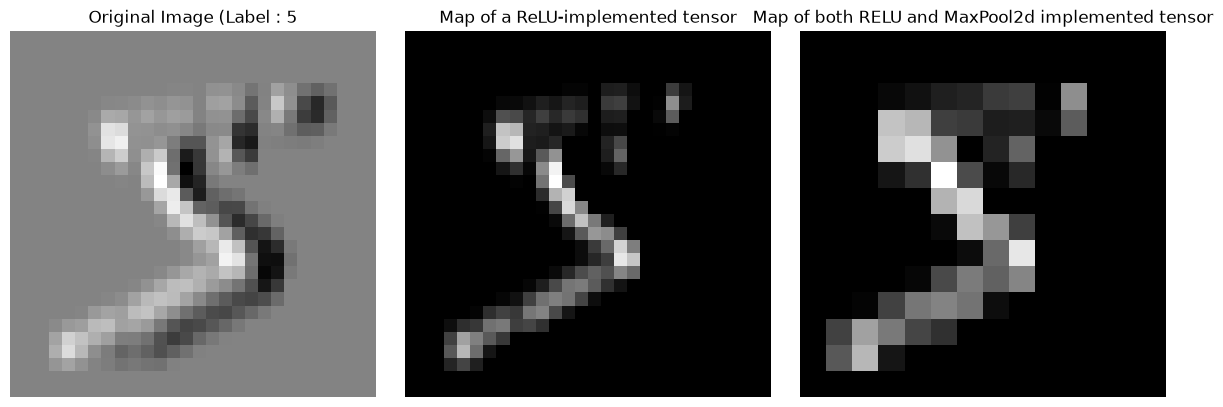

In [31]:
import torch
import torch.nn as nn #importing "torch.nn" (abbreviated "nn") means importing neural network "building blocks" (neural networks needed for the program to be able to identify edges)
import torchvision
import torchvision.transforms as transforms #Both needed to convert the 0 to 255 integer scale on pixels to 0.0 to 1.0 (that the neural networks can be able to read)
#QUESTION: Why do we need to mention "torchvision.transforms" alone when it is a part of the aformentioned "torchvision"
import matplotlib.pyplot as plt #imports matplotlib to be able to load the drawing library to depict output

transforming = transforms.ToTensor()

mnist_data = torchvision.datasets.MNIST( #when accessing a already-made dataset in PyTorch (torchvision.datasets), its "features" (root, train, download, transform) must be given
    root='.\data',
    train=True,
    download=True,
    transform=transforming
)

first_image, label = mnist_data[0] #mnist_data[0] has two components, an image of a number (first_image) and a label mentioning the number (label)

input_image = first_image.unsqueeze(0) #first_image is by default a 3D Tensor, "adding unsqueeze(0)" to "first_image" turns it into a 4D Tensor
#The above line was neccesary as Python neural networks are built strictly for processing batches and a 4D Tensor is formatted as "[Batch_Size, Color_Channels, Height, Width]"

convoluting = nn.Conv2d(in_channels=1, out_channels=1, kernel_size=3, padding=1) 
#QUESTION: Why do we care about preventing shrinking
#For the above line: nn.Conv2d() is required for the process of convolution to happen, "in_channels" represents the number of color channels for the input image (1), while "out_channels" represnts the number of outputted grids of numbers wanted (1), "kernel_size" is for the dimensions of the kernel (3 by 3) while "padding=1" ensures 1-pixel thick outermost layer of zeros ensuring output image is still 28 by 28 pixels (indicating no shrinking)

edge_kernel = torch.tensor([[[
    [-1.0, 0.0, 1.0],
    [-2.0, 0.0, 2.0],
    [-1.0, 0.0, 1.0]]]]) #.tensor() creates a custom tensor, the prescene of 4 "[]" indicates this is in a 4D shape even as kernel as 2D Tensors. This is because there are 4 features (in "convoluting) that the kernel must cater to ("in_channels" (number of color channels in the incoming image), "out_channels" (number of grid that one would like to output), "kernel_size" (dimensions), "padding" (number of outermost layers with 0s)

with torch.no_grad(): #mentioning "torch no_grad()" means temporary turning off the neural network's ability to learn patterns so that the kernel paramters can be set
    convoluting.weight = nn.Parameter(edge_kernel) #Assigning the kernel parameters using "convoluting.weight = nn.Parameter(edge_kernel)
    convoluting.bias.zero_() #Set bias to zero for pure kernel output

relu_layer = nn.ReLU() #application of the ReLU layer via "nn.ReLU" 
pool_layer = nn.MaxPool2d(kernel_size=2, stride=2) #application of the MaxPool2d layer via "nn.MaxPool2d"

conv_output = convoluting(input_image)
relu_output = relu_layer(conv_output) #Cancelling out the negative values of the convoluted "input_image" to ensure that no cancelling out of any "strong" values occur
pool_output = pool_layer(relu_output) #Application of "MaxPool2d" on "relu_output" (the modified convoluted "input_image" to save data while retaining the strongest "change" values

#Above are the 3 steps: Convoluting, Checking using ReLU and the applicatipon of MaxPool2D

conv_2dim = conv_output[0, 0].detach().numpy() #Conversion into 2D and numpy for matplotlib
relu_2dim = relu_output[0, 0].detach().numpy()
pool_2dim = pool_output[0, 0].detach().numpy()

fig, axes = plt.subplots(1, 3, figsize=(12, 4)) #"fig" represents "1, 3" indicating that we want 1 row and 3 columns and "axes" matches figsize(12 ,4) which is the combined size of the figures

#Graphs that will depict the 3 steps (step by step)
axes[0].imshow(conv_2dim, cmap='gray') 
axes[0].set_title(f"Original Image (Label : {label}")
axes[0].axis('off')

axes[1].imshow(relu_2dim, cmap='gray') 
axes[1].set_title("Map of a ReLU-implemented tensor")
axes[1].axis('off')

axes[2].imshow(pool_2dim, cmap='gray')
axes[2].set_title("Map of both RELU and MaxPool2d implemented tensor")
axes[2].axis('off')

plt.tight_layout() #Automatically resizes padding between graphs so that everything fits cleanly inside the display window (as having 3 graphs side by side may not be "clean" with default Matplotlib padding and handling
plt.show()




In [45]:
import torch
import torch.nn as nn

class SimpleCNN(nn.Module): #nn.Module is a standard way to create custom neural networks in Python
    def __init__(self):
        super(SimpleCNN, self).__init__() #declarding using "super()" that "self" is the parent class and SimpleCNN is the child class. We call "__init__" through "def __init__(self)" to assign "nn.Module" as "self" (father class)

        self.conv1 = nn.Conv2d(in_channels=1, out_channels=16, kernel_size=3, padding=1) #16 different 3x3 kernels are being multplied seperately against the original image which will result in 16 output images of 16 different filters
        self.relu = nn.ReLU() #application of the rectified linear unit
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2) #Application of the MaxPool2D
    
        self.conv2 = nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, padding=1) #second convolutional layer created to detect more complex features to dissect a number
    
        self.fc1 = nn.Linear(32 * 7 * 7, 128) #reduces 1568 pixels (pixels of inputs) into 128 internal decision values
        self.fc2 = nn.Linear(128, 10) #Outputs 10 numbers, each represnting the probability that a number is 0-9
        #Neural Networks in "full force"
        
    def forward(self, x): #plugging in "x" to "self"
        x = self.conv1(x)
        x = self.relu(x)
        x = self.pool(x)

        x = self.conv2(x)
        x = self.relu(x)
        x = self.pool(x)

        x = torch.flatten(x, start_dim=1) #maps needs to be converted to 1D tensor (only format that nn.Linear would understand)

        x = self.fc1(x)
        x = self.relu(x) #MaxPool2D() deliberatley ommitted as it is not applicable on a 1D tensor
        x = self.fc2(x)

        return x

#function just to test it out

if __name__ == "__main__": #essential for Python OOP functions
    model = SimpleCNN()
    dummy_input = torch.randn(1, 1, 28, 28) #creates one random 28 x 28 grayscale images with random pixel values
    output = model(dummy_input)
    print("Model created succesfully!")
    print(f"Output shape for 1 image: {output.shape}") #just ensuring that the model gives a succesful prediction

Model created succesfully!
Output shape for 1 image: torch.Size([1, 10])


In [55]:
import torch
import torch.nn as nn
import torch.optim as optim #torch.optim takes the loss function value and uses it to refine weights in functions such as fc1, fc2, conv1 and conv2
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader #DataLoader helps the compiler organize datasets into consistent, coherent, batches without "screwing up" data
import matplotlib.pyplot as plt

from model import SimpleCNN

transforming = transforms.Compose([ #".Compose()" allows for two ".transforms" commands to be implemented at the same time
    transforms.ToTensor(), #".ToTensor()" changes scale of pixels to [0, 1]
    transforms.Normalize(mean=(0.5,), std=(0.5,)) #using ".Normalize()", the mean and standard deviation are both set to 0.5 to change scale of pixels to [-1, 1]    
]) #Why do we need to do ".Normalize()" when it will change the scale from [0, 1] to [-1, 1] when that will bring the need for ReLU (hence making it redundant)

train_data = torchvision.datasets.MNIST(
    root = '.\data',
    train = True,
    download = True,
    transform = transforming
)

test_data = torchvision.datasets.MNIST(
    root = '.\data',
    train = False, #"train = False" for testing data
    download = True,
    transform = transforming
)

train_loader = DataLoader(dataset=train_data, batch_size=64) #Splitting up the training dataset into batches (groups) of 64 images
test_loader = DataLoader(dataset=test_data, batch_size=64) #Splitting up the testing dataset into batches/groups of 64 images

model = SimpleCNN() 
calculating = nn.CrossEntropyLoss() #"nn.CrossEntropyLoss()" takes the values that the neural network assigned to each of the final 10 values (0-9) and it converts into a percentage and then gives it a "score" based on its confidence for the correct number
optimizer = optim.Adam(model.parameters(), lr=0.001) #optim.(xxx)() takes "model.parameters()" (i.e. fc1, fc2 in "model") and shifts the weighted values in the network using "lr=0.001"

epochs = 5
history_loss = []
history_accuracy = []

print("Starting training loop...\n")

for epoch in range(epochs): #an epoch means passing through the training dataset of 60000 files once, range(epochs) is 5 implying that we do it 5 times
    model.train() #puts all model layers into training mode
    running_loss = 0.0 #this will keep track of the error loss to be counted later

    for batch_idx, (inputs, labels) in enumerate(train_loader):

        optimizer.zero_grad() #setting up all gradients equal to 0

        outputs = model(inputs) #implementing the groups of 64 images into SimpleCNN() as we have done "model = SimpleCNN()"

        loss = criterion(outputs, labels) #comparing the model's 64 prediction rows (outputs) to the real target digit (labels) before calculating a single average penalty number for each batch

        loss.backward() #using ".backward()", PyTorch traces back the penalty number through every operation (i.e. "fc1", "fc2")

        optimizer.step() #".step()" allows for the weight to be shifted by a small step to lower future prediction error

        running_loss += loss.item() #Adding that lost number directly into running loss total

        #calculate average loss for each epoch and put it into the list of "history_loss"
        epoch_loss = running_loss / len(train_loader)
        history_loss.append(epoch_loss)

        model.eval() #".eval()" sends model into evaluation mode
        correct = 0
        total = 0 #measures number of test batches iterated through (should be 10000 at the end)

        with torch.no_grad(): #".no_grad()" means disable gradient tracking for the sake of increasing evaluation speed
            for inputs, labels in test_loader: #for loop for the 10000 testing files
                outputs = model(inputs) #puts the images labelled "inputs" through SimpleCNN() "model()" to recieve an output of 10 raw prediction scores
                _, predicted = torch.max(outputs.dim, dim=1) #"_" represents the confidence score placed on each number ("_" means its omitted), "dim=1" represents an iteration through each horizontal row (of 0-9) for every image, torch.max() retrieves the value with the highest confidence score
                total += labels.size(0) #add the number of the 0th dimesion (as indicated through ".size(0)" for "labels" to total (which should 64 per batch and should end up at 10000)
                correct += (predicted == labels).sum().item() #through ".sum()" calculated all the times "predicted == labels" and ".item()" converts "tensor(2)" to "2"


        epoch_acc = 100 * correct / total #calculating the entire epoch accuracy 
        history_accuracy.append(epoch_acc) #appending epoch accuracy to a list named "history_accuracy"

        print(f"Epoch [{epoch+1}/{epochs}] - Loss: {epoch_loss:.4f} | Validation Accuracy: {epoch_acc:.2f}%") #epoch+1 will be 1 an not 0

        print("\nTraining Complete")

        fig, ax1 = plt.subplots(figsize=(8, 4))

        ax1.set_xlabel('Epoch')
        ax1.set_ylabel('Loss', color='tab:red')
        ax1.plot(range(1, epochs + 1), history_loss, color='tab:red', marker='o', label='Train Loss')
        ax1.tick_params(axis='y', labelcolor='tab:red') #change ticks on y-axis to a red color 

        ax2 = ax1.twinx()
        ax2.set_ylabel('Accuracy (%)', color='tab:blue')
        ax2.plot(range(1, epochs + 1), history_accuracy, color='tab:blue', marker='s', label='Val Accuracy')
        ax2.tick_params(axis='y', labelcolor='tab:blue') #change ticks on y-axis to a blue color

        plt.title('Training Loss vs Validation Accuracy')
        plt.tight_layout()
        plt.show()


        torch.show(model.state_dict(), 'mnist_cnn.pth')
        print("Model weights saved succesfully to 'mnist_cnn.pth'!")
        
#if __name__ == "__main__":
    #images, labels = next(iter(train_loader)) #iteration of a the 64 image sized batches
    #outputs = model(images) 
    #loss = calculating(outputs, labels) #Application of "nn.CrossEntropyLoss()"

    #print(f"Batch Images Shape: {images.shape}") #Should print [64, 1, 28, 28]
    #print(f"Batch Labels Shape: {labels.shape}") #Should print [64]
    #print(f"Initial Batch Loss: {loss.item():.4f}")


<>:17: SyntaxWarning: invalid escape sequence '\d'
<>:24: SyntaxWarning: invalid escape sequence '\d'
<>:17: SyntaxWarning: invalid escape sequence '\d'
<>:24: SyntaxWarning: invalid escape sequence '\d'
/var/folders/v6/1f2888zj1b38j_4l673jlcj00000gn/T/ipykernel_56760/2407264890.py:17: SyntaxWarning: invalid escape sequence '\d'
  root = '.\data',
/var/folders/v6/1f2888zj1b38j_4l673jlcj00000gn/T/ipykernel_56760/2407264890.py:24: SyntaxWarning: invalid escape sequence '\d'
  root = '.\data',


ModuleNotFoundError: No module named 'model'

In [63]:
import torch
import torchvision
import torchvision.transforms as transforms

from model import SimpleCNN

transforming = transforms.Compose(
    transforms.ToTensor(),
    transforms.Normalize(mean=(0.5,), std=(0.5,))
)

test_dataset = (root='.\data', train=False, download=True, transforms=transforming)
test_dataloader = torchvision.utils.data.DataLoader(dataset=test_dataset, batch_size=1, shuffle=True)

model = SimpleCNN()

model.load_state_dict(torch.load('mnist_cnn.pth')) #using ".load_state_dict" indicates that a state_dict from another file will get loaded while "torch.load()" is for a specific file

model.eval() #setting model to evaluation mode - it is important to ensure that batch normalization (".Normalize()") works in the way it is supposed to work when going through "prediction mode"

images, labels = next(iter(test_dataloader)) #iterating through each image of each batch of all testing files

with torch.no_grad(): #"torch.no_grad" ommits the gradient tracking per pixel to ensure higher evaluation speeds
    outputs = model(images) #placing the handwritten images through "model()" ("SimpleCNN()") and assigning it to variable "outputs"
    _, predicted = torch.max(outputs, dim=1) #for each handwritten image, see the value that the neural network has put maximum confidence in

print(f"True Label: {labels.item()}")
print(f"Model Predicted Label: {predicted.item()}")

if labels.item() == predicted.item():
    print("Correct number predicted!")
else:
    print("Predicted number does not match correct number")

SyntaxError: invalid syntax. Maybe you meant '==' or ':=' instead of '='? (2920957912.py, line 12)

In [ ]:
import streamlit as st
from streamlit_drawable_canvas import st_canvas
import numpy as np

st.set_page_config(page_title="MNIST Digit Recognizer", layout="centered")

st.title("Handwritten Digit Recognizer")
st.write("Draw a single digit (0-9) inside the black box below and click Predict!")

canvas_result = st_canvas(
    fill_color = "black",
    stroke_width = 20,
    stroke_color = "white",
    background_color = "black",
    height=280,
    width=280,
    drawing_mode="freedraw",
    key="canvas"
)

if canvas_result.image_data is not None:

    raw_image_array = canvas_result.image_data
    st.write(f"Raw Image Array Shape: {raw_image_array.shape}")

if np.any(raw_image_array[:, :, :3] > 0):
    st.success("Drawing detected on campus") #gives a success message
else:
    st.info("Draw a digit inside the box") #gives an information message